In [1]:
'''Generate and analyze AUC-ROC and precision-recall curves to evaluate classification thresholds, 
comparing model discriminatory power in imbalanced datasets for optimal threshold selection.'''

'Generate and analyze AUC-ROC and precision-recall curves to evaluate classification thresholds, \ncomparing model discriminatory power in imbalanced datasets for optimal threshold selection.'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (roc_curve,roc_auc_score,precision_recall_curve,average_precision_score,precision_score,
recall_score,f1_score,accuracy_score,confusion_matrix)

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

In [4]:
# load pharmacy dataset
df = pd.read_csv("global_pharmacy_sales_data.csv")

print("dataset shape:", df.shape)

display(df.head())

print("\ndataset information:")
df.info()

print("\nmissing values:")
display(df.isnull().sum())

print("\ntarget distribution:")
display(df['covid_flag'].value_counts())

print("\ntarget percentage:")
display(
    df['covid_flag'].value_counts(normalize=True)
    .mul(100)
    .round(2)
)

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0



dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177990 entries, 0 to 177989
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   date                   177990 non-null  object 
 1   year                   177990 non-null  int64  
 2   month                  177990 non-null  int64  
 3   day                    177990 non-null  int64  
 4   region                 177990 non-null  object 
 5   country                177990 non-null  object 
 6   category               177990 non-null  object 
 7   medicine               177990 non-null  object 
 8   age_group              177990 non-null  object 
 9   units_sold             177990 non-null  int64  
 10  unit_price             177990 non-null  float64
 11  stock_level            177990 non-null  int64  
 12  expiry_days_remaining  177990 non-null  int64  
 13  covid_flag             177990 non-null  int64  
dtypes: float64(1),

date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64


target distribution:


covid_flag
0    118627
1     59363
Name: count, dtype: int64


target percentage:


covid_flag
0    66.65
1    33.35
Name: proportion, dtype: float64

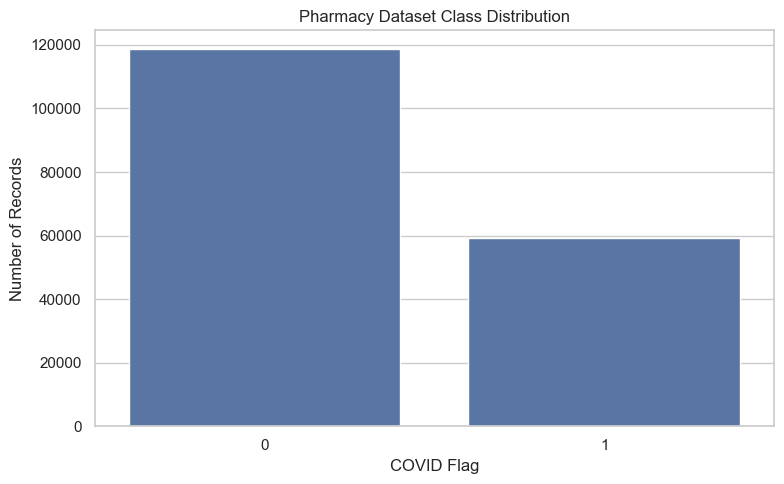

class imbalance ratio: 2.0


In [5]:
# calculate class distribution
class_counts = df['covid_flag'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_counts.index.astype(str),
    y=class_counts.values
)

plt.title('Pharmacy Dataset Class Distribution')
plt.xlabel('COVID Flag')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

# calculate imbalance ratio
imbalance_ratio = class_counts.max() / class_counts.min()

print("class imbalance ratio:", round(imbalance_ratio, 2))

In [6]:
# define target variable
target = 'covid_flag'

# remove target and date-related columns
excluded_columns = [
    target,
    'date',
    'year',
    'month',
    'day'
]

X = df.drop(
    columns=excluded_columns,
    errors='ignore'
)

y = df[target]

# identify feature types automatically
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("numerical features:", numeric_features)
print("\ncategorical features:", categorical_features)

# first split: 80% development, 20% final testing
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# second split: 75% training, 25% validation of development data
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=42,
    stratify=y_development
)

print("\ntraining records:", len(X_train))
print("validation records:", len(X_valid))
print("testing records:", len(X_test))

numerical features: ['units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining']

categorical features: ['region', 'country', 'category', 'medicine', 'age_group']

training records: 106794
validation records: 35598
testing records: 35598


In [7]:
# numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("automatic preprocessing pipeline created")

automatic preprocessing pipeline created


In [8]:
# define classification models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

print("classification models defined successfully")

classification models defined successfully


In [9]:
# train models and store probability predictions
trained_models = {}
validation_probabilities = {}
test_probabilities = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # train model
    pipeline.fit(X_train, y_train)

    # generate validation probabilities
    valid_prob = pipeline.predict_proba(X_valid)[:, 1]

    # generate test probabilities
    test_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline

    validation_probabilities[name] = valid_prob
    test_probabilities[name] = test_prob

    print(name, "training completed")

print("\nall models trained successfully")

Logistic Regression training completed
Random Forest training completed

all models trained successfully


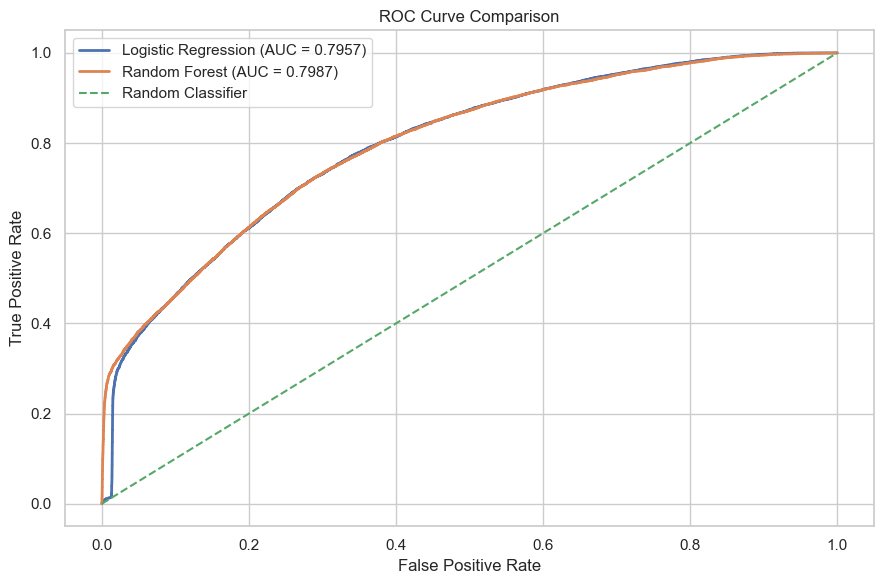

,Model,ROC AUC
0,Logistic Regression,0.7957
1,Random Forest,0.7987


In [10]:
# generate roc curves for all models
plt.figure(figsize=(9, 6))

roc_results = []

for name, probabilities in test_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    roc_results.append({
        'Model': name,
        'ROC AUC': auc_score
    })

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {auc_score:.4f})'
    )

# random classification reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.show()

roc_df = pd.DataFrame(roc_results)

display(roc_df.round(4))

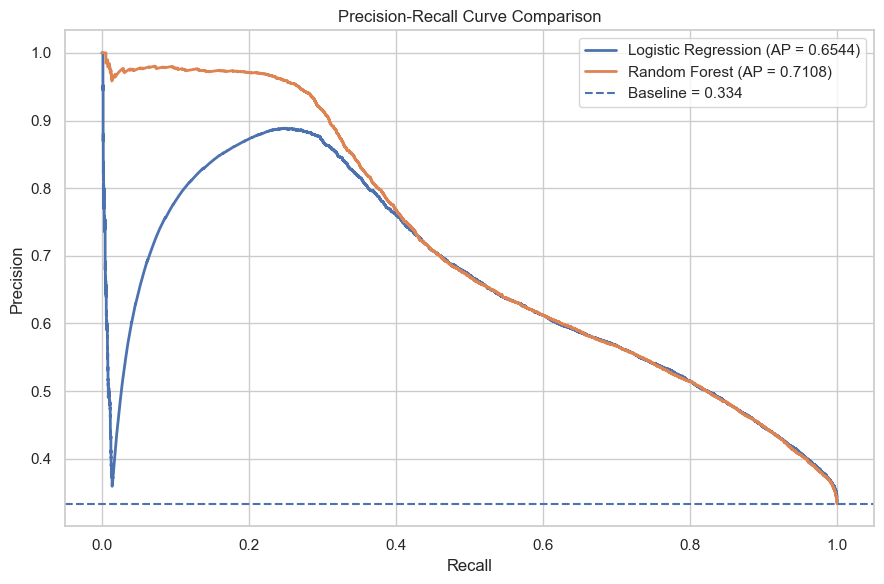

,Model,Average Precision
0,Logistic Regression,0.6544
1,Random Forest,0.7108


In [11]:
# generate precision-recall curves
plt.figure(figsize=(9, 6))

pr_results = []

for name, probabilities in test_probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probabilities
    )

    ap_score = average_precision_score(
        y_test,
        probabilities
    )

    pr_results.append({
        'Model': name,
        'Average Precision': ap_score
    })

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f'{name} (AP = {ap_score:.4f})'
    )

# positive class prevalence baseline
baseline = y_test.mean()

plt.axhline(
    baseline,
    linestyle='--',
    label=f'Baseline = {baseline:.3f}'
)

plt.title('Precision-Recall Curve Comparison')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.tight_layout()
plt.show()

pr_df = pd.DataFrame(pr_results)

display(pr_df.round(4))

model discriminatory power comparison:


,Model,ROC AUC,Average Precision,ROC Rank,PR Rank
1,Random Forest,0.7987,0.7108,1.0,1.0
0,Logistic Regression,0.7957,0.6544,2.0,2.0


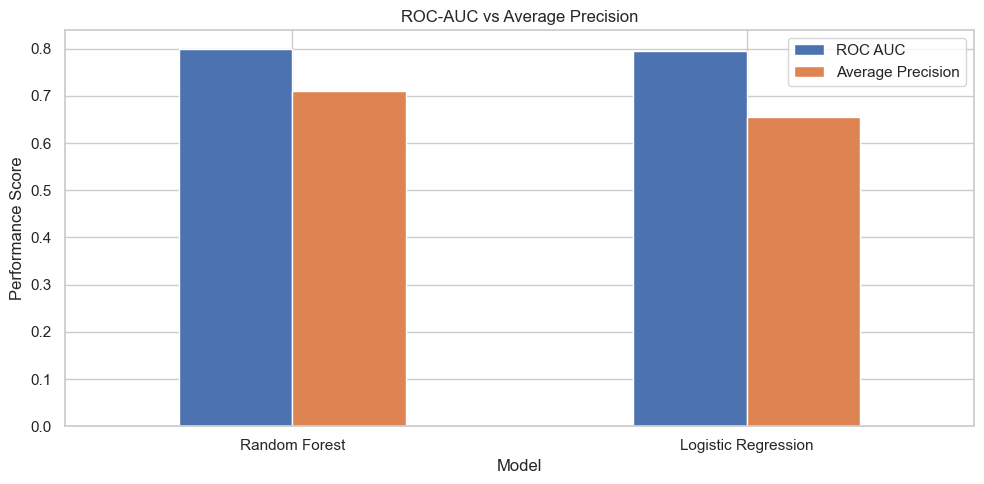

In [12]:
# combine both evaluation metrics
curve_comparison = pd.merge(
    roc_df,
    pr_df,
    on='Model'
)

curve_comparison['ROC Rank'] = (
    curve_comparison['ROC AUC']
    .rank(ascending=False, method='min')
)

curve_comparison['PR Rank'] = (
    curve_comparison['Average Precision']
    .rank(ascending=False, method='min')
)

curve_comparison = curve_comparison.sort_values(
    'Average Precision',
    ascending=False
)

print("model discriminatory power comparison:")

display(curve_comparison.round(4))

# visualize model comparison
curve_comparison.set_index('Model')[
    ['ROC AUC', 'Average Precision']
].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('ROC-AUC vs Average Precision')
plt.ylabel('Performance Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# evaluate multiple thresholds for each model
threshold_values = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

for name, probabilities in validation_probabilities.items():

    for threshold in threshold_values:

        # convert probabilities into class predictions
        y_pred = (
            probabilities >= threshold
        ).astype(int)

        # calculate confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_valid,
            y_pred,
            labels=[0, 1]
        ).ravel()

        # calculate classification metrics
        precision = precision_score(
            y_valid,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_valid,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_valid,
            y_pred,
            zero_division=0
        )

        fpr = fp / (fp + tn) if (fp + tn) else 0
        fnr = fn / (fn + tp) if (fn + tp) else 0

        threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'Precision': precision,
            'Recall': recall,
            'F1 Score': f1,
            'FPR': fpr,
            'FNR': fnr
        })

threshold_df = pd.DataFrame(threshold_results)

print("threshold evaluation results:")

display(threshold_df.round(4))

threshold evaluation results:


,Model,Threshold,Precision,Recall,F1 Score,FPR,FNR
0,Logistic Regression,0.10,0.3335,1.0000,0.5002,1.0000,0.0000
1,Logistic Regression,0.15,0.3350,1.0000,0.5018,0.9934,0.0000
2,Logistic Regression,0.20,0.3511,0.9984,0.5195,0.9235,0.0016
3,Logistic Regression,0.25,0.3815,0.9790,0.5490,0.7943,0.0210
4,Logistic Regression,0.30,0.4210,0.9355,0.5807,0.6438,0.0645
5,Logistic Regression,0.35,0.4668,0.8790,0.6098,0.5023,0.1210
6,Logistic Regression,0.40,0.5116,0.8176,0.6294,0.3905,0.1824
7,Logistic Regression,0.45,0.5504,0.7444,0.6329,0.3043,0.2556
8,Logistic Regression,0.50,0.5877,0.6653,0.6241,0.2336,0.3347
9,Logistic Regression,0.55,0.6286,0.5859,0.6065,0.1732,0.4141


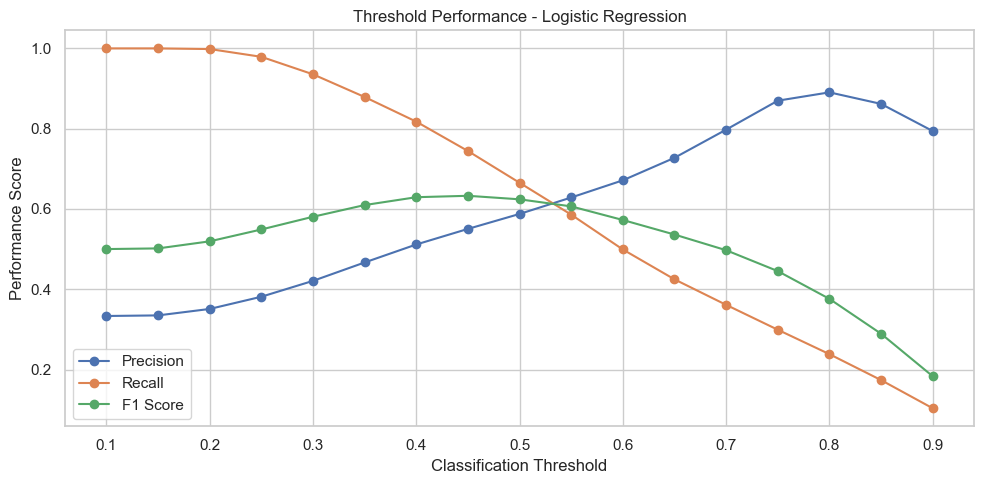

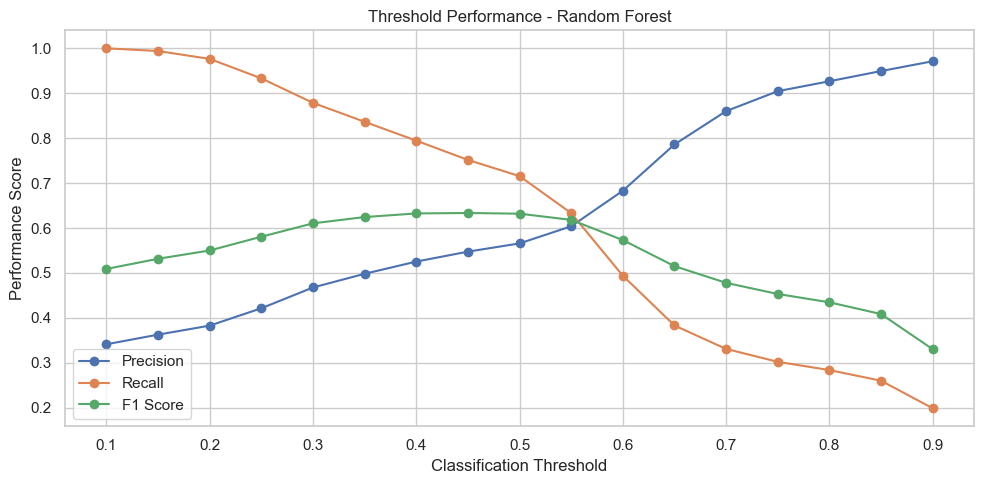

In [14]:
# compare precision, recall and f1 score across thresholds
for name in threshold_df['Model'].unique():

    model_data = threshold_df[
        threshold_df['Model'] == name
    ]

    plt.figure(figsize=(10, 5))

    for metric in ['Precision', 'Recall', 'F1 Score']:

        plt.plot(
            model_data['Threshold'],
            model_data[metric],
            marker='o',
            label=metric
        )

    plt.title(f'Threshold Performance - {name}')
    plt.xlabel('Classification Threshold')
    plt.ylabel('Performance Score')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

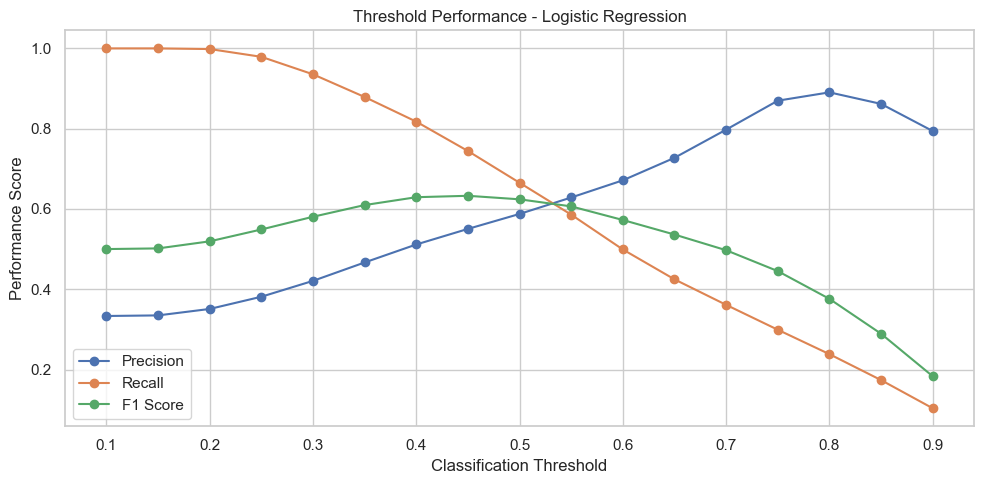

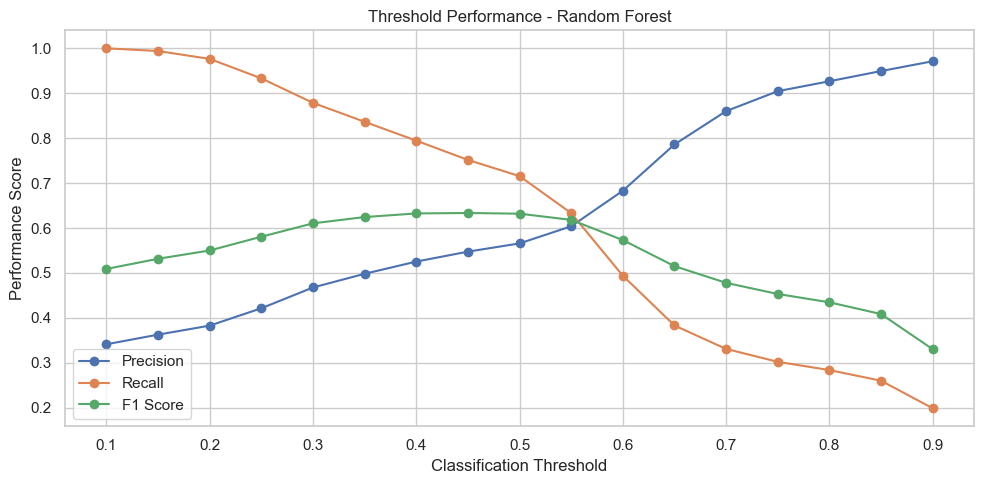

In [16]:
# select the best threshold for each model using validation data
optimal_thresholds = {}

for name in threshold_df['Model'].unique():

    model_data = threshold_df[
        threshold_df['Model'] == name
    ]

    best_row = model_data.loc[
        model_data['F1 Score'].idxmax()
    ]

    optimal_thresholds[name] = best_row['Threshold']

    print("\nmodel:", name)
    print("optimal threshold:", round(best_row['Threshold'], 3))
    print("precision:", round(best_row['Precision'], 4))
    print("recall:", round(best_row['Recall'], 4))
    print("f1 score:", round(best_row['F1 Score'], 4))
    print("fpr:", round(best_row['FPR'], 4))
    print("fnr:", round(best_row['FNR'], 4))


model: Logistic Regression
optimal threshold: 0.45
precision: 0.5504
recall: 0.7444
f1 score: 0.6329
fpr: 0.3043
fnr: 0.2556

model: Random Forest
optimal threshold: 0.45
precision: 0.5474
recall: 0.7514
f1 score: 0.6334
fpr: 0.3109
fnr: 0.2486


In [17]:
# evaluate selected thresholds on final test data
final_results = []

for name, probabilities in test_probabilities.items():

    selected_threshold = optimal_thresholds[name]

    # apply selected threshold
    y_pred = (
        probabilities >= selected_threshold
    ).astype(int)

    # calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # calculate final metrics
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    fpr = fp / (fp + tn) if (fp + tn) else 0
    fnr = fn / (fn + tp) if (fn + tp) else 0

    final_results.append({
        'Model': name,
        'Selected Threshold': selected_threshold,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'FPR': fpr,
        'FNR': fnr,
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'Average Precision': average_precision_score(
            y_test,
            probabilities
        )
    })

final_df = pd.DataFrame(final_results)

print("final test performance using optimal thresholds:")

display(final_df.round(4))

final test performance using optimal thresholds:


,Model,Selected Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR,ROC AUC,Average Precision
0,Logistic Regression,0.45,0.7078,0.5456,0.7404,0.6283,0.3086,0.2596,0.7957,0.6544
1,Random Forest,0.45,0.7067,0.5441,0.7451,0.6289,0.3125,0.2549,0.7987,0.7108


,Model,Threshold Type,Threshold,Precision,Recall,F1 Score
0,Logistic Regression,Default,0.50,0.5844,0.6576,0.6188
1,Logistic Regression,Optimized,0.45,0.5456,0.7404,0.6283
2,Random Forest,Default,0.50,0.5617,0.7084,0.6266
3,Random Forest,Optimized,0.45,0.5441,0.7451,0.6289


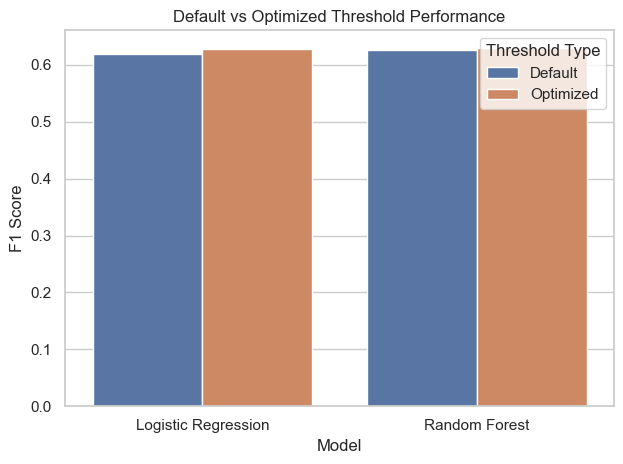

In [18]:
# compare default and optimized thresholds
threshold_comparison = []

for name, probabilities in test_probabilities.items():

    for threshold_type, threshold in [
        ('Default', 0.50),
        ('Optimized', optimal_thresholds[name])
    ]:

        y_pred = (
            probabilities >= threshold
        ).astype(int)

        threshold_comparison.append({
            'Model': name,
            'Threshold Type': threshold_type,
            'Threshold': threshold,
            'Precision': precision_score(
                y_test, y_pred, zero_division=0
            ),
            'Recall': recall_score(
                y_test, y_pred, zero_division=0
            ),
            'F1 Score': f1_score(
                y_test, y_pred, zero_division=0
            )
        })

comparison_df = pd.DataFrame(threshold_comparison)

display(comparison_df.round(4))

# visualize f1 score improvements
sns.barplot(
    data=comparison_df,
    x='Model',
    y='F1 Score',
    hue='Threshold Type'
)

plt.title('Default vs Optimized Threshold Performance')
plt.tight_layout()
plt.show()

In [21]:
# select the model with the highest average precision
best_model_row = final_df.loc[
    final_df['Average Precision'].idxmax()
]

best_model = best_model_row['Model']

best_threshold = best_model_row['Selected Threshold']

print("FINAL AUC-ROC AND PRECISION-RECALL ANALYSIS")

print("\nbest model:", best_model)

print("optimal threshold:", round(best_threshold, 3))

print("roc auc:", round(best_model_row['ROC AUC'], 4))

print(
    "average precision:",
    round(best_model_row['Average Precision'], 4)
)

print("precision:", round(best_model_row['Precision'], 4))
print("recall:", round(best_model_row['Recall'], 4))
print("f1 score:", round(best_model_row['F1 Score'], 4))

print("\nmodel diagnosis:")

if best_model_row['FPR'] > best_model_row['FNR']:
    print("the model produces relatively more false positive errors.")

elif best_model_row['FNR'] > best_model_row['FPR']:
    print("the model produces relatively more false negative errors.")

else:
    print("the false positive and false negative rates are balanced.")

print("\nrefinement recommendations:")

if best_model_row['Precision'] < 0.80:
    print("- improve precision by investigating false positive predictions.")

if best_model_row['Recall'] < 0.80:
    print("- improve recall by investigating false negative predictions.")

if best_model_row['F1 Score'] < 0.80:
    print("- investigate model parameters and feature quality.")

if best_model_row['ROC AUC'] < 0.70:
    print("- improve the model's ability to distinguish both classes.")

if best_model_row['Average Precision'] < 0.70:
    print("- investigate positive class detection and class imbalance.")

print("\ncomplete curve and threshold analysis finished.")

FINAL AUC-ROC AND PRECISION-RECALL ANALYSIS

best model: Random Forest
optimal threshold: 0.45
roc auc: 0.7987
average precision: 0.7108
precision: 0.5441
recall: 0.7451
f1 score: 0.6289

model diagnosis:
the model produces relatively more false positive errors.

refinement recommendations:
- improve precision by investigating false positive predictions.
- improve recall by investigating false negative predictions.
- investigate model parameters and feature quality.

complete curve and threshold analysis finished.
